**Looped transformers series:** **01 Universal Transformer** · [02 Adaptive Computation Time](02_act_halting.ipynb) · [03 Recurrent depth](03_recurrent_depth.ipynb) · [04 Fixed point (DEQ)](04_deq_fixed_point.ipynb) · [05 Mixture-of-Recursions](05_mixture_of_recursions.ipynb) · [06 Relaxed recursion](06_relaxed_recursion.ipynb) · [07 Scratchpad memory](07_scratchpad_memory.ipynb) · [08 Layer-sharing schedules](08_layer_sharing.ipynb)

# Looped transformers 01 - the Universal Transformer, from scratch

A normal transformer is a **stack** of $N$ different blocks, each used once. The **Universal Transformer** (Dehghani et al., 2018) keeps only **one** block and applies it $T$ times in a loop, adding a small "which step am I on?" signal (the *depth embedding*) before every pass. That decouples two things a stack ties together: **parameters** (how much the model can store) and **compute** (how many times it thinks about each token). In this notebook we build every piece in plain PyTorch - attention by hand, a pre-norm block, the depth embedding, the looped language model - and then *measure* what looping buys on a tiny toy corpus and on ~real English text (Python's own docstrings).

| What you will learn | Where |
|---|---|
| Stacked vs looped: parameters vs compute | §1, §4 |
| Causal multi-head self-attention written by hand, checked against `nn.MultiheadAttention` | §3 |
| The sinusoidal depth (step) embedding $E^t$ | §2, §3 |
| Why weight tying = summing per-pass gradients (proved numerically with `torch.func.functional_call`) | §4 |
| A character-level LM training loop with no framework | §5, §6 |
| The "logit lens": how predictions improve pass by pass | §7 |
| Controlled experiments at equal parameters, and with/without depth embedding | §8 |

**Prerequisites:** Python, PyTorch basics (tensors, `nn.Module`, autograd, an optimizer loop), and having heard of attention.

**Estimated runtime:** about 6 minutes on an idle laptop CPU (2 threads); 13 minutes when the CPU was shared with other jobs. Everything is CPU-only and seeded.

In [1]:
# Setup: only the standard library, torch, numpy and matplotlib.
import math
import time
import random
import importlib
import inspect
import re

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.func import functional_call
import matplotlib.pyplot as plt

torch.set_num_threads(2)          # other jobs share this machine; keep CPU usage modest


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)


set_seed(0)
NOTEBOOK_START = time.time()
print("torch", torch.__version__, "| threads", torch.get_num_threads())

torch 2.13.0 | threads 2


## 1. Intuition

Think of editing an essay. A **stacked** transformer is like passing the essay through 6 different editors, each with their own specialty, each reading it once. A **looped** (Universal) transformer is like giving the essay to **one** editor and asking them to read it 6 times. The single editor has fewer "skills" stored in their head (fewer parameters), but they still get 6 chances to improve the draft (the same compute). To help them know whether this is the 1st read or the 6th, we hand them a sticky note with the pass number on it - that is the **depth embedding**.

Two numbers describe any of these models:

* **Parameters** = how many distinct weights exist. Stack of $N$ blocks: $N\times$ block size. Looped: $1\times$ block size, whatever $T$ is.
* **Compute** = how many block applications happen per token. Stack: $N$. Looped: $T$.

So the question this whole series asks is: **if compute is the same, how much do we lose by sharing parameters - and what do we gain?**

```mermaid
flowchart LR
    subgraph Stacked["Stacked transformer (N different blocks)"]
        direction LR
        A0["embed(x)"] --> B1["Block 1"] --> B2["Block 2"] --> B3["..."] --> BN["Block N"] --> H1["LN + head"]
    end
    subgraph Looped["Universal / looped transformer (one block, T passes)"]
        direction LR
        C0["h0 = embed(x)"] --> ADD(("+ E^t"))
        ADD --> BLK["Shared Block<br/>(same weights every pass)"]
        BLK -->|"t < T: h_t"| ADD
        BLK -->|"t = T"| H2["LN + head -> logits"]
    end
```

## 2. The math

**Shapes.** $B$ = batch size, $L$ = sequence length (characters), $d$ = model width, $H$ = number of heads, $d_h = d/H$ = width per head, $V$ = vocabulary size.

**Embedding.** Token ids $x \in \{0,\dots,V-1\}^{B\times L}$ become vectors with a token table $W_{\text{tok}}\in\mathbb{R}^{V\times d}$ and a learned position table $P\in\mathbb{R}^{L_{\max}\times d}$:
$$h_0[b,i] = W_{\text{tok}}[x_{b,i}] + P[i] \qquad h_0 \in \mathbb{R}^{B\times L\times d}$$

**The loop.** For pass $t = 1,\dots,T$, with the *same* block weights $\theta$ every time:
$$h_t = \text{Block}_\theta\!\left(h_{t-1} + E^t\right), \qquad \text{logits} = \text{LN}_f(h_T)\,W_{\text{out}} \in \mathbb{R}^{B\times L\times V}$$

**Depth embedding** $E^t\in\mathbb{R}^{d}$ (broadcast over $B$ and $L$) is the same sinusoid as the original Transformer's position code, but indexed by the *pass number* $t$ instead of the token position:
$$E^t_{2k} = \sin\!\left(\frac{t}{10000^{2k/d}}\right), \qquad E^t_{2k+1} = \cos\!\left(\frac{t}{10000^{2k/d}}\right), \qquad k = 0,\dots,\tfrac d2-1$$
Low dimensions oscillate fast (distinguish neighbouring passes), high dimensions oscillate slowly (a smooth "how deep am I" signal). It has no parameters.

**Pre-norm block.** With $\text{LN}$ = LayerNorm:
$$z' = z + \text{Attn}(\text{LN}_1(z)), \qquad \text{Block}(z) = z' + \text{MLP}(\text{LN}_2(z')), \qquad \text{MLP}(u) = W_2\,\text{GELU}(W_1 u + b_1) + b_2$$
with $W_1\in\mathbb{R}^{4d\times d}$, $W_2\in\mathbb{R}^{d\times 4d}$.

**Causal multi-head attention.** For input $u\in\mathbb{R}^{B\times L\times d}$: $Q = uW_Q$, $K = uW_K$, $V = uW_V$, each reshaped to $(B, H, L, d_h)$. For each head,
$$A = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_h}} + M\right)\in\mathbb{R}^{B\times H\times L\times L}, \qquad M_{ij} = \begin{cases}0 & j\le i\\ -\infty & j>i\end{cases}$$
$$\text{Attn}(u) = \text{concat}_h(A\,V)\,W_O \in \mathbb{R}^{B\times L\times d}$$
The mask $M$ is what makes it a *language model*: position $i$ may only look at positions $\le i$, so it cannot peek at the character it is supposed to predict.

**Loss.** Next-character cross-entropy, and the same thing in bits:
$$\mathcal{L} = -\frac{1}{BL}\sum_{b,i}\log p_\theta(x_{b,i+1}\mid x_{b,\le i}), \qquad \text{bits/char} = \mathcal{L}/\ln 2$$

**Parameters vs compute.** One block has $4d^2 + 4d$ (attention) $+ 8d^2 + 5d$ (MLP) $+ 4d$ (two LayerNorms) $= 12d^2 + 13d$ parameters. A stack of $N$ blocks has $N(12d^2+13d)$; a looped model has $12d^2+13d$ for **any** $T$. Compute per token is $\propto N$ or $\propto T$ block applications.

## 3. Building blocks from scratch

### 3.1 Causal multi-head self-attention, by hand

We use one `nn.Linear` that produces $Q$, $K$ and $V$ at once (its weight is $[W_Q; W_K; W_V]$ stacked, shape $(3d, d)$), split the result into heads, and do the scaled dot product ourselves. The layout deliberately matches `nn.MultiheadAttention` so we can copy weights across and compare numbers.

In [2]:
class CausalSelfAttention(nn.Module):
    # Multi-head causal self-attention written out step by step.

    def __init__(self, d_model: int, n_heads: int) -> None:
        super().__init__()
        assert d_model % n_heads == 0, "d_model must split evenly into heads"
        self.d_model = d_model
        self.n_heads = n_heads
        self.d_head = d_model // n_heads
        self.qkv = nn.Linear(d_model, 3 * d_model)   # weight rows = [W_Q; W_K; W_V]
        self.out = nn.Linear(d_model, d_model)       # W_O
        self.record_weights = False                  # set True to keep the attention map for plotting
        self.last_weights = None

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        B, L, d = x.shape
        q, k, v = self.qkv(x).split(d, dim=-1)                     # 3 x (B, L, d)
        # (B, L, d) -> (B, L, H, d_h) -> (B, H, L, d_h): each head gets its own slice of width d_h
        q = q.view(B, L, self.n_heads, self.d_head).transpose(1, 2)
        k = k.view(B, L, self.n_heads, self.d_head).transpose(1, 2)
        v = v.view(B, L, self.n_heads, self.d_head).transpose(1, 2)
        scores = q @ k.transpose(-2, -1) / math.sqrt(self.d_head)  # (B, H, L, L)
        # True above the diagonal = "future" positions that must be hidden
        future = torch.triu(torch.ones(L, L, dtype=torch.bool, device=x.device), diagonal=1)
        scores = scores.masked_fill(future, float("-inf"))          # exp(-inf) = 0 after softmax
        weights = scores.softmax(dim=-1)                            # each row sums to 1
        if self.record_weights:
            self.last_weights = weights.detach()
        y = weights @ v                                             # (B, H, L, d_h)
        y = y.transpose(1, 2).reshape(B, L, d)                      # concatenate heads
        return self.out(y)

**Check 1 - it matches PyTorch's own implementation.** We copy our weights into `nn.MultiheadAttention` and give it the same causal mask. For `nn.MultiheadAttention`, a **boolean** `attn_mask` means `True = not allowed to attend`, which is exactly our `future` matrix.

In [3]:
set_seed(0)
B, L, d, H = 2, 10, 32, 4
x = torch.randn(B, L, d)

attn = CausalSelfAttention(d, H)
mha = nn.MultiheadAttention(d, H, batch_first=True)
with torch.no_grad():
    mha.in_proj_weight.copy_(attn.qkv.weight)   # same [W_Q; W_K; W_V] layout
    mha.in_proj_bias.copy_(attn.qkv.bias)
    mha.out_proj.weight.copy_(attn.out.weight)
    mha.out_proj.bias.copy_(attn.out.bias)

causal_mask = torch.triu(torch.ones(L, L, dtype=torch.bool), diagonal=1)
ours = attn(x)
theirs, _ = mha(x, x, x, attn_mask=causal_mask, need_weights=False)
max_diff = (ours - theirs).abs().max().item()
print("output shape:", tuple(ours.shape), "| max |ours - nn.MultiheadAttention| =", f"{max_diff:.2e}")
assert ours.shape == (B, L, d)
assert torch.allclose(ours, theirs, atol=1e-5), "hand-written attention disagrees with nn.MultiheadAttention"

output shape: (2, 10, 32) | max |ours - nn.MultiheadAttention| = 1.79e-07


**Check 2 - causality (no future leakage).** If we change the input at position 6, the outputs at positions 0-5 must not move at all; positions 6-9 are allowed to change. We also check that every attention row sums to 1 and that the upper triangle is exactly 0.

In [4]:
x2 = x.clone()
x2[:, 6] += torch.randn(B, d)          # perturb ONE position
out1, out2 = attn(x), attn(x2)
change_per_pos = (out1 - out2).abs().amax(dim=(0, 2))
print("max output change per position:", [f"{c:.1e}" for c in change_per_pos.tolist()])
assert torch.all(change_per_pos[:6] == 0), "past positions saw the future!"
assert torch.all(change_per_pos[6:] > 0)

attn.record_weights = True
_ = attn(x)
w = attn.last_weights                  # (B, H, L, L)
attn.record_weights = False
assert torch.allclose(w.sum(-1), torch.ones(B, H, L))
assert torch.all(w.triu(diagonal=1) == 0)
print("attention rows sum to 1 and the upper triangle is exactly zero")

max output change per position: ['0.0e+00', '0.0e+00', '0.0e+00', '0.0e+00', '0.0e+00', '0.0e+00', '2.1e-01', '1.5e-01', '2.1e-01', '1.3e-01']
attention rows sum to 1 and the upper triangle is exactly zero


### 3.2 MLP and the pre-norm block

The block is the reference block of this series: `LayerNorm -> attention -> residual`, then `LayerNorm -> MLP(GELU) -> residual`. **Pre-norm** (normalising *before* each sub-layer, not after) keeps the residual stream $h$ an untouched running sum, which is what makes it safe to apply the same block many times.

In [5]:
class MLP(nn.Module):
    def __init__(self, d_model: int, mlp_ratio: int = 4) -> None:
        super().__init__()
        self.fc1 = nn.Linear(d_model, mlp_ratio * d_model)
        self.fc2 = nn.Linear(mlp_ratio * d_model, d_model)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.fc2(F.gelu(self.fc1(x)))


class Block(nn.Module):
    # Pre-norm transformer block: x + Attn(LN(x)), then + MLP(LN(.)).

    def __init__(self, d_model: int, n_heads: int, mlp_ratio: int = 4) -> None:
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = CausalSelfAttention(d_model, n_heads)
        self.ln2 = nn.LayerNorm(d_model)
        self.mlp = MLP(d_model, mlp_ratio)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = x + self.attn(self.ln1(x))
        x = x + self.mlp(self.ln2(x))
        return x


def count_params(module: nn.Module) -> int:
    return sum(p.numel() for p in module.parameters())

In [6]:
block = Block(d, H)
y = block(x)
expected = 12 * d * d + 13 * d
print("block output:", tuple(y.shape), "| params:", count_params(block), "| formula 12d^2+13d =", expected)
assert y.shape == x.shape
assert count_params(block) == expected

# the block is still causal: perturbing position 6 leaves positions 0-5 untouched
assert torch.all((block(x) - block(x2))[:, :6] == 0)

block output: (2, 10, 32) | params: 12704 | formula 12d^2+13d = 12704


### 3.3 The sinusoidal depth embedding $E^t$

A shared block cannot tell pass 1 from pass 5 by itself: it sees only $h$. We add $E^t$ (from §2) to the residual stream before pass $t$. Row 0 of the table is never used (passes start at 1).

table shape: (17, 64)
cos(E^t, E^{t+1}) for t=1..5: [0.966, 0.966, 0.966, 0.966, 0.966]


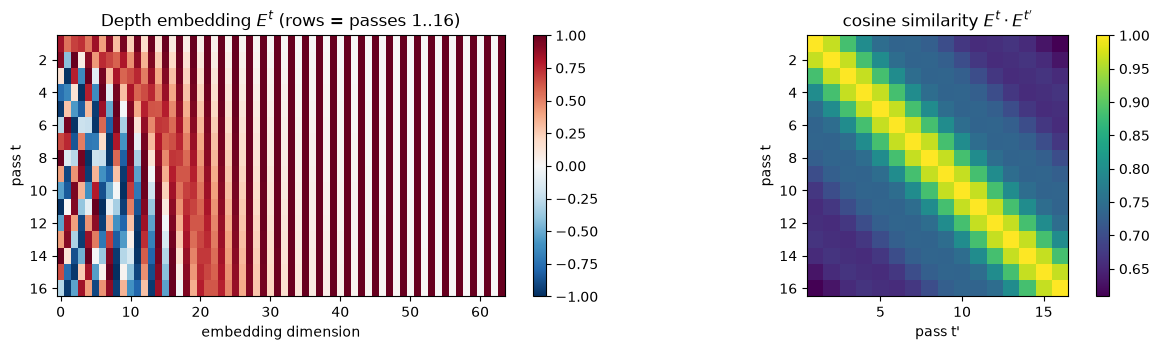

In [7]:
def sinusoidal_depth_embedding(n_steps: int, d_model: int) -> torch.Tensor:
    # Returns a (n_steps + 1, d_model) table; row t is E^t.
    assert d_model % 2 == 0
    t = torch.arange(n_steps + 1, dtype=torch.float32).unsqueeze(1)          # (n_steps+1, 1)
    k = torch.arange(0, d_model, 2, dtype=torch.float32)                     # 0, 2, 4, ... = 2k
    freq = 1.0 / (10000.0 ** (k / d_model))                                  # (d/2,)
    table = torch.zeros(n_steps + 1, d_model)
    table[:, 0::2] = torch.sin(t * freq)
    table[:, 1::2] = torch.cos(t * freq)
    return table


E = sinusoidal_depth_embedding(16, 64)
print("table shape:", tuple(E.shape))
# check one entry against the formula, computed by hand
t_chk, k_chk = 3, 5
assert math.isclose(E[t_chk, 2 * k_chk].item(), math.sin(t_chk / 10000 ** (2 * k_chk / 64)), rel_tol=1e-5)
assert math.isclose(E[t_chk, 2 * k_chk + 1].item(), math.cos(t_chk / 10000 ** (2 * k_chk / 64)), rel_tol=1e-5)

# how different are neighbouring passes? cosine similarity between E^t and E^{t+1}
cos_next = F.cosine_similarity(E[1:-1], E[2:], dim=-1)
print("cos(E^t, E^{t+1}) for t=1..5:", [round(c, 3) for c in cos_next[:5].tolist()])

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
im = ax[0].imshow(E[1:].numpy(), aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1,
                  extent=[-0.5, 63.5, 16.5, 0.5])
ax[0].set_xlabel("embedding dimension"); ax[0].set_ylabel("pass t")
ax[0].set_title("Depth embedding $E^t$ (rows = passes 1..16)")
fig.colorbar(im, ax=ax[0])
sim = F.cosine_similarity(E[1:].unsqueeze(1), E[1:].unsqueeze(0), dim=-1)
im2 = ax[1].imshow(sim.numpy(), cmap="viridis", extent=[0.5, 16.5, 16.5, 0.5])
ax[1].set_xlabel("pass t'"); ax[1].set_ylabel("pass t")
ax[1].set_title("cosine similarity $E^t \\cdot E^{t'}$")
fig.colorbar(im2, ax=ax[1])
plt.tight_layout(); plt.show()

**Reading the heatmap.** The left columns flip sign every pass or two (fast frequencies), the right columns barely change (slow frequencies, they are almost constant $\cos\approx 1$). The similarity map on the right shows that **nearby passes get similar codes and distant passes get different ones** - but because half the dimensions are almost constant, every pair is still fairly similar (all values well above 0). That will matter for the depth-embedding experiment.

## 4. The full model

`LoopedLM` covers both families with two knobs: `n_distinct` = how many *different* blocks, `n_loops` = how many times the group is applied.

* stacked transformer with 4 layers: `n_distinct=4, n_loops=1`
* Universal Transformer with 6 passes: `n_distinct=1, n_loops=6`

The forward pass is split into `embed` / `step` / `readout` so we can reuse the pieces (for the gradient experiment and the logit lens).

**Initialisation note.** We keep PyTorch's default `nn.Embedding` init ($\mathcal{N}(0,1)$), so the token embedding has per-dimension scale $\approx 1$, comparable to $E^t\in[-1,1]$. If the token embedding were initialised tiny (e.g. std 0.02, a common GPT choice) the fixed depth signal would swamp the content at the start of training.

In [8]:
class LoopedLM(nn.Module):
    # Character LM: h0 = embed(x); h_t = Blocks(h_{t-1} + E^t) for t = 1..T; logits = head(LN(h_T)).

    def __init__(self, vocab_size: int, d_model: int = 128, n_heads: int = 4, n_distinct: int = 1,
                 n_loops: int = 4, max_len: int = 64, use_depth_emb: bool = True, max_loops: int = 32) -> None:
        super().__init__()
        self.n_loops = n_loops
        self.use_depth_emb = use_depth_emb
        self.tok_emb = nn.Embedding(vocab_size, d_model)
        self.pos_emb = nn.Embedding(max_len, d_model)
        self.blocks = nn.ModuleList([Block(d_model, n_heads) for _ in range(n_distinct)])
        self.ln_f = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, vocab_size)
        # a buffer: saved with the model and moved with .to(), but not a trainable parameter
        self.register_buffer("depth_table", sinusoidal_depth_embedding(max_loops, d_model))

    def embed(self, idx: torch.Tensor) -> torch.Tensor:
        positions = torch.arange(idx.shape[1], device=idx.device)
        return self.tok_emb(idx) + self.pos_emb(positions)              # (B, L, d)

    def add_depth(self, h: torch.Tensor, t: int) -> torch.Tensor:
        return h + self.depth_table[t] if self.use_depth_emb else h

    def step(self, h: torch.Tensor, t: int) -> torch.Tensor:
        h = self.add_depth(h, t)
        for block in self.blocks:          # one "pass" = the whole group of distinct blocks
            h = block(h)
        return h

    def readout(self, h: torch.Tensor) -> torch.Tensor:
        return self.head(self.ln_f(h))                                  # (B, L, V)

    def forward(self, idx: torch.Tensor, n_loops: int | None = None,
                return_hidden: bool = False):
        T = self.n_loops if n_loops is None else n_loops               # T can be changed at test time
        h = self.embed(idx)
        hidden = [h]
        for t in range(1, T + 1):
            h = self.step(h, t)
            hidden.append(h)
        logits = self.readout(h)
        return (logits, hidden) if return_hidden else logits

    def block_applications(self, n_loops: int | None = None) -> int:
        return len(self.blocks) * (self.n_loops if n_loops is None else n_loops)

In [9]:
V_demo = 100       # placeholder vocabulary size for this table; the real one comes in §5
idx = torch.randint(0, V_demo, (2, 16))
m = LoopedLM(V_demo, d_model=128, n_loops=6)
logits, hidden = m(idx, return_hidden=True)
print("logits:", tuple(logits.shape), "| hidden states kept:", len(hidden), "(h_0 .. h_6)")
assert logits.shape == (2, 16, V_demo) and len(hidden) == 7

# causality of the whole looped model: changing token 10 must not change logits at positions < 10
idx2 = idx.clone(); idx2[:, 10] = (idx2[:, 10] + 1) % V_demo
assert torch.allclose(m(idx)[:, :10], m(idx2)[:, :10]), "future-token leakage through the loop"
print("looped model is causal: logits at positions 0..9 unchanged when token 10 changes")

rows = []
for T in (1, 2, 4, 6, 8, 12, 16):
    stacked = LoopedLM(V_demo, 128, n_distinct=T, n_loops=1, use_depth_emb=False)
    looped = LoopedLM(V_demo, 128, n_distinct=1, n_loops=T)
    rows.append((T, count_params(stacked), stacked.block_applications(), count_params(looped), looped.block_applications()))
print(f"\n{'depth':>5} | {'stacked params':>14} | {'stacked compute':>15} | {'looped params':>13} | {'looped compute':>14}")
for T, ps, cs, pl, cl in rows:
    print(f"{T:>5} | {ps:>14,} | {cs:>15} | {pl:>13,} | {cl:>14}")

logits: (2, 16, 100) | hidden states kept: 7 (h_0 .. h_6)
looped model is causal: logits at positions 0..9 unchanged when token 10 changes

depth | stacked params | stacked compute | looped params | looped compute
    1 |        232,420 |               1 |       232,420 |              1
    2 |        430,692 |               2 |       232,420 |              2
    4 |        827,236 |               4 |       232,420 |              4
    6 |      1,223,780 |               6 |       232,420 |              6
    8 |      1,620,324 |               8 |       232,420 |              8
   12 |      2,413,412 |              12 |       232,420 |             12
   16 |      3,206,500 |              16 |       232,420 |             16


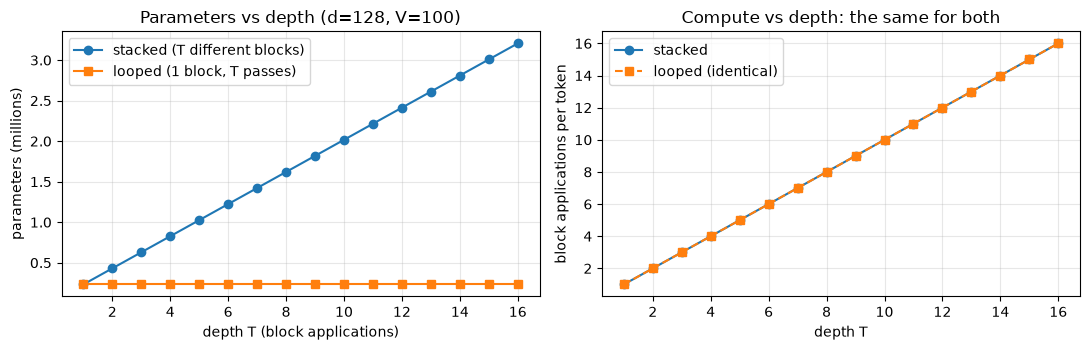

one block = 198,272 params; embeddings + head = 34,148 params


In [10]:
Ts = np.arange(1, 17)
block_p = count_params(Block(128, 4))
emb_head_p = count_params(LoopedLM(V_demo, 128, n_distinct=1, n_loops=1)) - block_p
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(Ts, (emb_head_p + Ts * block_p) / 1e6, "o-", label="stacked (T different blocks)")
ax[0].plot(Ts, np.full_like(Ts, emb_head_p + block_p) / 1e6, "s-", label="looped (1 block, T passes)")
ax[0].set_xlabel("depth T (block applications)"); ax[0].set_ylabel("parameters (millions)")
ax[0].set_title("Parameters vs depth (d=128, V=100)"); ax[0].legend(); ax[0].grid(alpha=0.3)
ax[1].plot(Ts, Ts, "o-", label="stacked"); ax[1].plot(Ts, Ts, "s--", label="looped (identical)")
ax[1].set_xlabel("depth T"); ax[1].set_ylabel("block applications per token")
ax[1].set_title("Compute vs depth: the same for both"); ax[1].legend(); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f"one block = {block_p:,} params; embeddings + head = {emb_head_p:,} params")

### 4.1 Weight tying, seen through gradients

When one block is used $T$ times, what does its gradient look like? Autograd treats each use as a separate node in the graph, and the chain rule **adds** the contributions:
$$\frac{\partial\mathcal{L}}{\partial\theta} = \sum_{t=1}^{T}\frac{\partial\mathcal{L}}{\partial\theta_t}\bigg|_{\theta_1=\dots=\theta_T=\theta}$$
where $\theta_t$ is "the copy of the weights used at pass $t$". We can make this concrete: give each pass its **own copy** of the weights with `torch.func.functional_call(block, params_t, (h,))`, which runs the block's forward with a dictionary of tensors we choose instead of its stored parameters. Then (a) the loss is identical, (b) the per-pass gradients **sum exactly** to the shared gradient, and (c) we can look at how much each pass contributes.

In [11]:
set_seed(1)
T_grad = 8
model_g = LoopedLM(V_demo, d_model=64, n_heads=4, n_loops=T_grad)
shared_block = model_g.blocks[0]
xb = torch.randint(0, V_demo, (8, 32))
yb = torch.randint(0, V_demo, (8, 32))

# (a) normal forward: one shared set of weights
loss_shared = F.cross_entropy(model_g(xb).flatten(0, 1), yb.flatten())
names = [n for n, _ in shared_block.named_parameters()]
grads_shared = torch.autograd.grad(loss_shared, list(shared_block.parameters()))

# (b) untied forward: pass t uses its own copy (same values) of every block parameter
copies = [{n: p.detach().clone().requires_grad_(True) for n, p in shared_block.named_parameters()}
          for _ in range(T_grad)]
h = model_g.embed(xb)
for t in range(1, T_grad + 1):
    h = model_g.add_depth(h, t)
    h = functional_call(shared_block, copies[t - 1], (h,))
loss_untied = F.cross_entropy(model_g.readout(h).flatten(0, 1), yb.flatten())
flat_copies = [copies[t][n] for t in range(T_grad) for n in names]
flat_grads = torch.autograd.grad(loss_untied, flat_copies)
per_pass = [dict(zip(names, flat_grads[t * len(names):(t + 1) * len(names)])) for t in range(T_grad)]

assert torch.allclose(loss_shared, loss_untied), "the untied copy should compute the same function"
worst = 0.0
for n, g_shared in zip(names, grads_shared):
    g_sum = sum(per_pass[t][n] for t in range(T_grad))
    worst = max(worst, (g_sum - g_shared).abs().max().item())
    assert torch.allclose(g_sum, g_shared, atol=1e-6, rtol=1e-4), n
print(f"loss shared = {loss_shared.item():.6f}, loss untied = {loss_untied.item():.6f}")
print(f"sum over passes of per-pass grads == shared grad for all {len(names)} tensors (max abs diff {worst:.1e})")

loss shared = 4.759763, loss untied = 4.759763
sum over passes of per-pass grads == shared grad for all 12 tensors (max abs diff 3.7e-09)


 attention: per-pass grad norm ['0.045', '0.049', '0.050', '0.050', '0.050', '0.049', '0.049', '0.049']
       MLP: per-pass grad norm ['0.071', '0.068', '0.063', '0.059', '0.057', '0.055', '0.055', '0.055']
LayerNorms: per-pass grad norm ['0.006', '0.006', '0.006', '0.005', '0.005', '0.005', '0.005', '0.005']


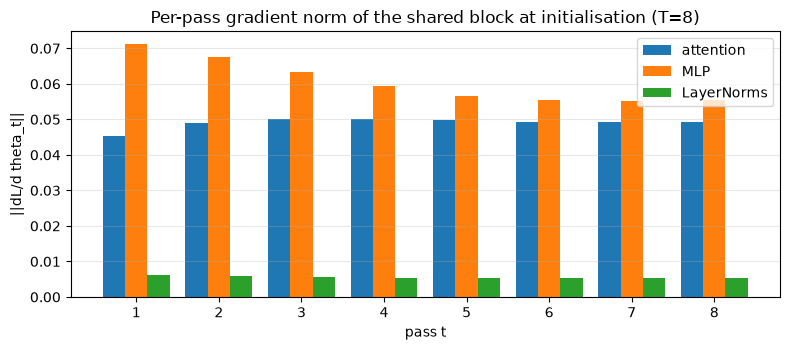

In [12]:
def grad_norm(gdict: dict, keys: list[str]) -> float:
    return math.sqrt(sum(gdict[k].pow(2).sum().item() for k in keys))

groups = {
    "attention": [n for n in names if n.startswith("attn")],
    "MLP": [n for n in names if n.startswith("mlp")],
    "LayerNorms": [n for n in names if n.startswith("ln")],
}
passes = np.arange(1, T_grad + 1)
fig, ax = plt.subplots(figsize=(8, 3.6))
width = 0.27
for j, (gname, keys) in enumerate(groups.items()):
    norms = [grad_norm(per_pass[t], keys) for t in range(T_grad)]
    ax.bar(passes + (j - 1) * width, norms, width, label=gname)
    print(f"{gname:>10}: per-pass grad norm", [f"{v:.3f}" for v in norms])
ax.set_xlabel("pass t"); ax.set_ylabel("||dL/d theta_t||")
ax.set_title(f"Per-pass gradient norm of the shared block at initialisation (T={T_grad})")
ax.legend(); ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()

**What the numbers say.** The per-pass gradients sum exactly to the shared one (max difference $3.7\times10^{-9}$, i.e. float rounding), so **weight tying is nothing more than "add up what every pass wants"**. At initialisation no pass dominates: attention gradients are 0.045-0.050 at every one of the 8 passes, and MLP gradients fall only gently from 0.071 (pass 1) to 0.055 (pass 8). Because of the pre-norm residual stream, early passes are not starved of gradient even though they are 8 blocks away from the loss. Be careful with this picture, though: it is one random batch on an untrained model, and it says nothing about what happens later in training.

## 5. Data

Two corpora:

* **(a) Toy corpus** - 4 sentences of 48 characters with exactly two genuine choice points (`model`/`robot` and `write`/`spell`). Small enough to memorise and to look at every prediction.
* **(b) Docstring corpus** - real English (technical) text that ships with Python: the docstrings of 30 standard-library modules. We split it 90/10 *by position* (the last 10% is validation, never seen in training) and measure **validation bits per character**.

The tokenizer is the simplest possible: every distinct character is one token.

In [13]:
TOY_CORPUS = [
    "the tiny model learned to write this sentence :)",
    "the tiny robot learned to write this sentence :)",
    "the tiny model learned to spell this sentence :)",
    "the tiny robot learned to spell this sentence :)",
]  # 48 chars each; two genuine choice points: model/robot and write/spell


def docstring_corpus() -> str:
    # Real English text that ships with Python: docstrings of standard-library modules.
    import importlib, inspect, re
    mods = ["collections", "itertools", "functools", "json", "re", "string", "textwrap", "pathlib",
            "datetime", "statistics", "random", "heapq", "bisect", "typing", "dataclasses", "argparse",
            "logging", "enum", "fractions", "decimal", "csv", "shutil", "tempfile", "contextlib", "abc",
            "copy", "pprint", "difflib", "calendar", "zipfile"]
    docs = []
    for m in mods:
        for _, obj in inspect.getmembers(importlib.import_module(m)):
            d = inspect.getdoc(obj)
            if d and len(d) > 60 and (inspect.isfunction(obj) or inspect.isclass(obj) or inspect.ismethod(obj)):
                docs.append(d)
    return re.sub(r"\s+", " ", " ".join(dict.fromkeys(docs)))


text = docstring_corpus()
print(f"docstring corpus: {len(text):,} characters, {len(set(text))} distinct")
print("sample:", repr(text[:200]))
assert all(len(s) == 48 for s in TOY_CORPUS)

docstring corpus: 142,997 characters, 98 distinct
sample: 'A ChainMap groups multiple dicts (or other mappings) together to create a single, updateable view. The underlying mappings are stored in a list. That list is public and can be accessed or updated usin'


In [14]:
class CharTokenizer:
    # Maps each distinct character to an integer id and back.

    def __init__(self, text: str) -> None:
        self.chars = sorted(set(text))
        self.stoi = {c: i for i, c in enumerate(self.chars)}
        self.itos = {i: c for i, c in enumerate(self.chars)}

    @property
    def vocab_size(self) -> int:
        return len(self.chars)

    def encode(self, s: str) -> list[int]:
        return [self.stoi[c] for c in s]

    def decode(self, ids: list[int]) -> str:
        return "".join(self.itos[i] for i in ids)


# one vocabulary for both corpora (built from all characters; fine for a char-level model)
tok = CharTokenizer(text + "".join(TOY_CORPUS))
V = tok.vocab_size
assert tok.decode(tok.encode(TOY_CORPUS[0])) == TOY_CORPUS[0]

data = torch.tensor(tok.encode(text), dtype=torch.long)
n_train = int(0.9 * len(data))
train_data, val_data = data[:n_train], data[n_train:]
print(f"vocab size V = {V} | train {len(train_data):,} chars | val {len(val_data):,} chars")

SEQ_LEN = 64


def get_batch(split_data: torch.Tensor, batch_size: int, seq_len: int = SEQ_LEN) -> tuple[torch.Tensor, torch.Tensor]:
    # Random windows; the target is the input shifted left by one character.
    starts = torch.randint(0, len(split_data) - seq_len - 1, (batch_size,))
    x = torch.stack([split_data[s:s + seq_len] for s in starts])
    y = torch.stack([split_data[s + 1:s + seq_len + 1] for s in starts])
    return x, y


xb, yb = get_batch(train_data, 4)
assert xb.shape == (4, SEQ_LEN) and torch.equal(xb[:, 1:], yb[:, :-1])
print("x:", repr(tok.decode(xb[0].tolist())))
print("y:", repr(tok.decode(yb[0].tolist())))

# fixed validation set: consecutive non-overlapping windows covering the validation split
n_val_windows = (len(val_data) - 1) // SEQ_LEN
VAL_X = torch.stack([val_data[i * SEQ_LEN:(i + 1) * SEQ_LEN] for i in range(n_val_windows)])
VAL_Y = torch.stack([val_data[i * SEQ_LEN + 1:(i + 1) * SEQ_LEN + 1] for i in range(n_val_windows)])
print(f"validation: {n_val_windows} windows x {SEQ_LEN} chars = {VAL_X.numel():,} predictions")

# toy corpus as a (4, 48) tensor: input = first 47 chars, target = last 47 chars
toy = torch.tensor([tok.encode(s) for s in TOY_CORPUS])
TOY_X, TOY_Y = toy[:, :-1], toy[:, 1:]
print("toy batch:", tuple(TOY_X.shape))

vocab size V = 98 | train 128,697 chars | val 14,300 chars
x: 'All the methods provided by the class are considered an implemen'
y: 'll the methods provided by the class are considered an implement'
validation: 223 windows x 64 chars = 14,272 predictions
toy batch: (4, 47)


## 6. The training loop

Written out explicitly: sample a batch, forward, cross-entropy, backward, clip the gradient norm, AdamW step. The learning rate warms up linearly for the first 5% of steps and then follows a cosine decay to 10% of its peak. Evaluation computes the average cross-entropy over the whole fixed validation set and converts it to bits per character.

In [15]:
def lr_at(step: int, total: int, peak: float, warmup_frac: float = 0.05) -> float:
    warmup = max(1, int(warmup_frac * total))
    if step < warmup:
        return peak * (step + 1) / warmup
    progress = (step - warmup) / max(1, total - warmup)
    return peak * (0.1 + 0.9 * 0.5 * (1 + math.cos(math.pi * progress)))


@torch.no_grad()
def evaluate_bpc(model: LoopedLM, n_loops: int | None = None, max_windows: int | None = None,
                 batch_size: int = 128) -> float:
    model.eval()
    X = VAL_X if max_windows is None else VAL_X[:max_windows]
    Y = VAL_Y if max_windows is None else VAL_Y[:max_windows]
    total_nll, total_count = 0.0, 0
    for i in range(0, len(X), batch_size):
        logits = model(X[i:i + batch_size], n_loops=n_loops)
        total_nll += F.cross_entropy(logits.flatten(0, 1), Y[i:i + batch_size].flatten(), reduction="sum").item()
        total_count += Y[i:i + batch_size].numel()
    model.train()
    return total_nll / total_count / math.log(2)


def train(model: LoopedLM, batch_fn, steps: int, peak_lr: float = 3e-3, eval_every: int = 0,
          eval_windows: int = 128, log_every: int = 0) -> dict:
    # batch_fn() -> (x, y). Returns a history dict with per-step train loss and periodic val bpc.
    opt = torch.optim.AdamW(model.parameters(), lr=peak_lr, betas=(0.9, 0.98), weight_decay=0.01)
    history = {"train_loss": [], "val_step": [], "val_bpc": []}
    t0 = time.time()
    model.train()
    for step in range(steps):
        for group in opt.param_groups:
            group["lr"] = lr_at(step, steps, peak_lr)
        x, y = batch_fn()
        logits = model(x)
        loss = F.cross_entropy(logits.flatten(0, 1), y.flatten())
        opt.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)   # guards against rare loss spikes
        opt.step()
        history["train_loss"].append(loss.item())
        if eval_every and (step + 1) % eval_every == 0:
            history["val_step"].append(step + 1)
            history["val_bpc"].append(evaluate_bpc(model, max_windows=eval_windows))
        if log_every and (step + 1) % log_every == 0:
            print(f"  step {step + 1:>5} | loss {loss.item():.4f} | {time.time() - t0:5.1f}s")
    history["seconds"] = time.time() - t0
    return history

### 6.1 Train a Universal Transformer on the toy corpus

One block ($d=64$, 4 heads), looped $T=6$ times, with depth embedding. The batch is simply all 4 sentences.

**What is the best possible loss?** Each sentence has 47 predictions. 45 are fully determined by the prefix; 2 are coin flips (`m`/`r` after "the tiny ", `w`/`s` after "learned to "), where the best you can do is $p=0.5$, i.e. $\ln 2$ nats. So the floor is $2\ln 2/47 \approx 0.0295$ nats per character, and the best possible argmax accuracy is $(45 + 2\cdot 0.5)/47 \approx 97.9\%$.

toy model: 66,850 parameters, 6 block applications


  step   100 | loss 0.0334 |   1.6s


  step   200 | loss 0.0309 |   3.4s


  step   300 | loss 0.0302 |   4.9s


  step   400 | loss 0.0300 |   6.5s
final loss 0.0300 nats | floor 0.0295 | 6.5s


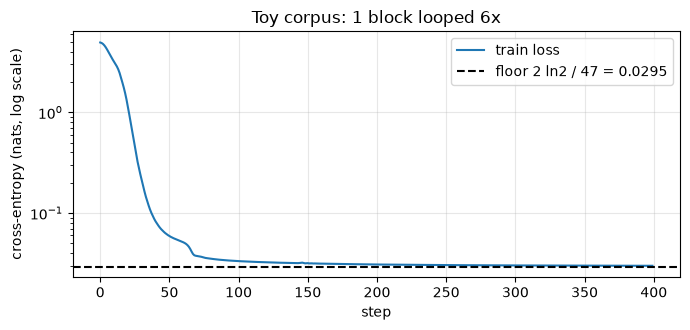

In [16]:
set_seed(0)
TOY_T = 6
toy_model = LoopedLM(V, d_model=64, n_heads=4, n_distinct=1, n_loops=TOY_T, max_len=64)
print(f"toy model: {count_params(toy_model):,} parameters, {toy_model.block_applications()} block applications")
toy_hist = train(toy_model, lambda: (TOY_X, TOY_Y), steps=400, peak_lr=3e-3, log_every=100)
TOY_FLOOR = 2 * math.log(2) / 47
print(f"final loss {toy_hist['train_loss'][-1]:.4f} nats | floor {TOY_FLOOR:.4f} | {toy_hist['seconds']:.1f}s")

plt.figure(figsize=(7, 3.4))
plt.semilogy(toy_hist["train_loss"], label="train loss")
plt.axhline(TOY_FLOOR, color="k", ls="--", label=f"floor 2 ln2 / 47 = {TOY_FLOOR:.4f}")
plt.xlabel("step"); plt.ylabel("cross-entropy (nats, log scale)")
plt.title("Toy corpus: 1 block looped 6x"); plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

In [17]:
@torch.no_grad()
def greedy_continue(model: LoopedLM, prefix: str, n_chars: int) -> str:
    model.eval()
    ids = tok.encode(prefix)
    for _ in range(n_chars):
        logits = model(torch.tensor([ids]))
        ids.append(int(logits[0, -1].argmax()))
    model.train()
    return tok.decode(ids)

for prefix in ["the tiny m", "the tiny r", "the tiny robot learned to s"]:
    print(f"{prefix!r:32} -> {greedy_continue(toy_model, prefix, 48 - len(prefix))!r}")

'the tiny m'                     -> 'the tiny model learned to spell this sentence :)'
'the tiny r'                     -> 'the tiny robot learned to spell this sentence :)'
'the tiny robot learned to s'    -> 'the tiny robot learned to spell this sentence :)'


## 7. Look inside

### 7.1 Logit lens: decode after every pass

The "logit lens" applies the final read-out $\text{LN}_f(\cdot)W_{\text{out}}$ to the **intermediate** hidden states $h_0, h_1, \dots, h_T$. The model was only trained to make $h_T$ readable, so early passes are not guaranteed to mean anything - but in a looped model every pass writes into the same residual stream with the same weights, so we can ask: *how many passes does each position need before it gets the right answer?*

pass | mean p(correct) | argmax accuracy
   0 |           0.125 |          0.309
   1 |           0.854 |          0.979
   2 |           0.974 |          0.979
   3 |           0.977 |          0.979
   4 |           0.978 |          0.979
   5 |           0.978 |          0.979
   6 |           0.978 |          0.979


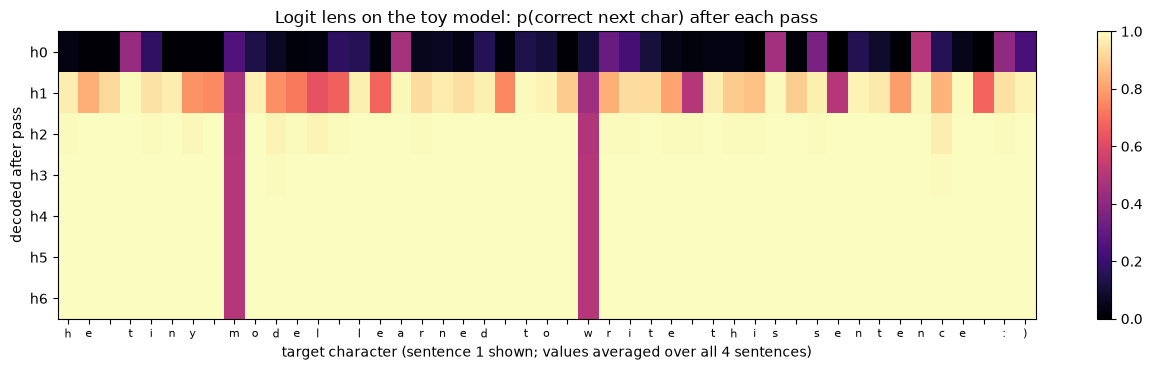

In [18]:
@torch.no_grad()
def logit_lens(model: LoopedLM, x: torch.Tensor, y: torch.Tensor, n_loops: int | None = None):
    # Returns (passes+1, L) arrays: prob of the correct char and argmax accuracy, averaged over the batch.
    model.eval()
    _, hidden = model(x, n_loops=n_loops, return_hidden=True)
    p_correct, acc = [], []
    for h in hidden:
        probs = model.readout(h).softmax(-1)                          # (B, L, V)
        p_correct.append(probs.gather(-1, y.unsqueeze(-1)).squeeze(-1).mean(0))
        acc.append((probs.argmax(-1) == y).float().mean(0))
    model.train()
    return torch.stack(p_correct).numpy(), torch.stack(acc).numpy()


toy_p, toy_acc = logit_lens(toy_model, TOY_X, TOY_Y)
print("pass | mean p(correct) | argmax accuracy")
for t in range(TOY_T + 1):
    print(f"{t:>4} | {toy_p[t].mean():>15.3f} | {toy_acc[t].mean():>14.3f}")

fig, ax = plt.subplots(figsize=(13, 3.8))
im = ax.imshow(toy_p, aspect="auto", cmap="magma", vmin=0, vmax=1)
ax.set_yticks(range(TOY_T + 1)); ax.set_yticklabels([f"h{t}" for t in range(TOY_T + 1)])
ax.set_xticks(range(47)); ax.set_xticklabels(list(TOY_CORPUS[0][1:]), fontsize=8)
ax.set_xlabel("target character (sentence 1 shown; values averaged over all 4 sentences)")
ax.set_ylabel("decoded after pass")
ax.set_title("Logit lens on the toy model: p(correct next char) after each pass")
fig.colorbar(im, ax=ax)
plt.tight_layout(); plt.show()

In [19]:
# where are the remaining mistakes after the last pass?
final_acc = toy_acc[-1]
wrong = [(i, TOY_CORPUS[0][: i + 1], final_acc[i]) for i in range(47) if final_acc[i] < 1.0]
print("positions not 100% correct after the last pass:")
for i, prefix, a in wrong:
    print(f"  target position {i + 1:>2} (after {prefix!r}): accuracy {a:.2f}, p(correct) {toy_p[-1][i]:.2f}")
# the passes each position needs to first reach p(correct) > 0.9
first_good = [next((t for t in range(TOY_T + 1) if toy_p[t][i] > 0.9), None) for i in range(47)]
counts = {t: first_good.count(t) for t in range(TOY_T + 1)}
print("number of positions first reaching p>0.9 at pass t:", counts, "| never:", first_good.count(None))

positions not 100% correct after the last pass:
  target position  9 (after 'the tiny '): accuracy 0.50, p(correct) 0.50
  target position 26 (after 'the tiny model learned to '): accuracy 0.50, p(correct) 0.50
number of positions first reaching p>0.9 at pass t: {0: 0, 1: 25, 2: 20, 3: 0, 4: 0, 5: 0, 6: 0} | never: 2


**What the logit lens shows.**
* $h_0$ (embedding only, no attention) gets 30.9% of next characters right: it can only guess from the current character, like a bigram model.
* After **pass 1**, argmax accuracy is already **97.9%**, which is the best possible (§6.1). The mean probability on the correct character is 0.854.
* **Pass 2** sharpens the confidence (p = 0.974). Passes 3-6 add almost nothing (0.977 → 0.978, against a ceiling of 0.979).
* 25 positions are confident (p > 0.9) after pass 1 and 20 more need pass 2. **None needs passes 3-6.**
* The only remaining "errors" are the two genuine coin flips: position 9 (`m`/`r` after "the tiny ") and position 26 (`w`/`s` after "learned to "). There the model outputs exactly p = 0.50, which is correct behaviour, not a bug. Greedy decoding therefore always picks the same branch ("spell").

So on this task the model **uses about 2 of its 6 passes and the rest sit idle**. A fixed $T$ wastes compute on easy tokens, which is the motivation for adaptive halting ([notebook 02](02_act_halting.ipynb)).

### 7.2 Same weights, different behaviour per pass

The block's weights are identical at every pass, yet its *attention pattern* can change because its input $h_{t-1}+E^t$ changes. Below: the attention map of head 0 at pass 1 and at pass $T$ for the first toy sentence.

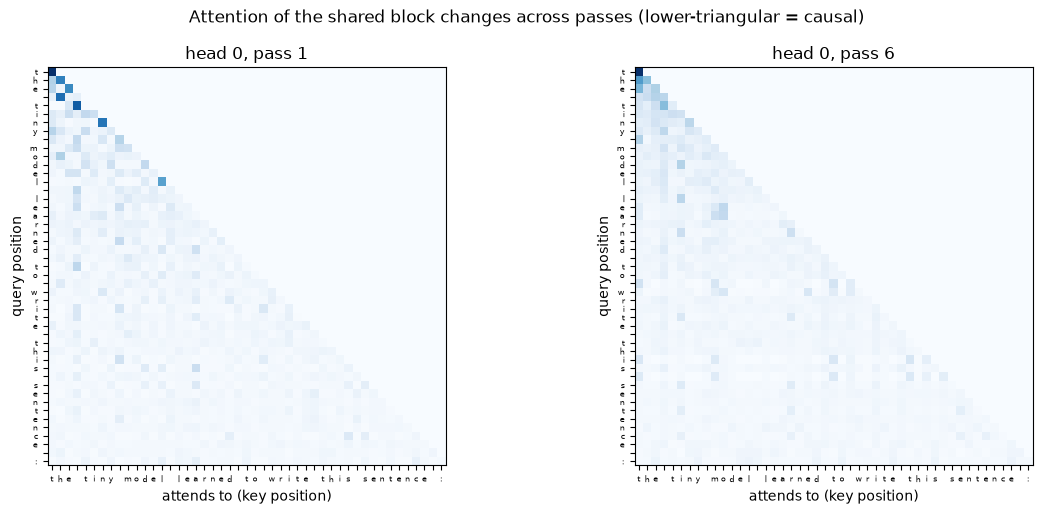

mean total-variation distance between attention at pass t-1 and t: ['0.225', '0.175', '0.075', '0.046', '0.035']


In [20]:
attn_layer = toy_model.blocks[0].attn
maps = []
with torch.no_grad():
    toy_model.eval()
    h = toy_model.embed(TOY_X[:1])
    attn_layer.record_weights = True
    for t in range(1, TOY_T + 1):
        h = toy_model.step(h, t)
        maps.append(attn_layer.last_weights[0])        # (H, L, L)
    attn_layer.record_weights = False
    toy_model.train()
maps = torch.stack(maps)                               # (T, H, L, L)

fig, ax = plt.subplots(1, 2, figsize=(12, 5.2))
labels = list(TOY_CORPUS[0][:-1])
for a, t in zip(ax, [0, TOY_T - 1]):
    a.imshow(maps[t, 0].numpy(), cmap="Blues", vmin=0, vmax=1)
    a.set_title(f"head 0, pass {t + 1}")
    a.set_xticks(range(47)); a.set_xticklabels(labels, fontsize=6)
    a.set_yticks(range(47)); a.set_yticklabels(labels, fontsize=6)
    a.set_xlabel("attends to (key position)"); a.set_ylabel("query position")
plt.suptitle("Attention of the shared block changes across passes (lower-triangular = causal)")
plt.tight_layout(); plt.show()

# how much does the attention pattern move between passes? total-variation distance, averaged
tv = [(0.5 * (maps[t] - maps[t - 1]).abs().sum(-1)).mean().item() for t in range(1, TOY_T)]
print("mean total-variation distance between attention at pass t-1 and t:", [f"{v:.3f}" for v in tv])

## 8. Experiments on the docstring corpus

All runs share: $d=128$, 4 heads, batch 32 windows of 64 characters, `STEPS` optimizer steps, peak LR $3\times10^{-3}$, the same seed and therefore the same batches. Validation bits/char is measured on the full held-out 10%.

**Experiment A - equal parameters, more compute.** One block used once ($T=1$) vs the same-size block looped $T=2,4,6$. For reference we add a **4-block stack** (4x the block parameters, same compute as $T=4$).

**Experiment B - with vs without depth embedding** at $T=4$, plus a stress test: evaluate the trained $T=4$ models with a *different* number of passes at test time (no retraining).

In [21]:
STEPS = 600
BATCH = 32
EXP_D = 128


def run_config(name: str, n_distinct: int, n_loops: int, use_depth_emb: bool, seed: int = 0) -> dict:
    set_seed(seed)
    model = LoopedLM(V, d_model=EXP_D, n_heads=4, n_distinct=n_distinct, n_loops=n_loops,
                     use_depth_emb=use_depth_emb)
    gen = torch.Generator().manual_seed(1234 + seed)       # identical batches for every config

    def batch_fn() -> tuple[torch.Tensor, torch.Tensor]:
        starts = torch.randint(0, len(train_data) - SEQ_LEN - 1, (BATCH,), generator=gen)
        x = torch.stack([train_data[s:s + SEQ_LEN] for s in starts])
        y = torch.stack([train_data[s + 1:s + SEQ_LEN + 1] for s in starts])
        return x, y

    hist = train(model, batch_fn, steps=STEPS, eval_every=100)
    result = {
        "name": name, "model": model, "hist": hist,
        "params": count_params(model),
        "block_params": sum(count_params(b) for b in model.blocks),
        "compute": model.block_applications(),
        "val_bpc": evaluate_bpc(model),
        # mean of the last 50 training-batch losses, in bits: compare with val to see the generalisation gap
        "train_bpc": sum(hist["train_loss"][-50:]) / 50 / math.log(2),
        "seconds": hist["seconds"],
    }
    print(f"{name:<26} params {result['params']:>8,} | compute {result['compute']} | "
          f"train {result['train_bpc']:.3f} | val {result['val_bpc']:.4f} bits/char | {result['seconds']:.1f}s")
    return result


configs = [
    ("1 block x1", 1, 1, True, 0),
    ("1 block looped x2", 1, 2, True, 0),
    ("1 block looped x4", 1, 4, True, 0),
    ("1 block looped x6", 1, 6, True, 0),
    ("4 stacked blocks x1", 4, 1, False, 0),
    ("1 block looped x4, no E^t", 1, 4, False, 0),
    ("1 block x1, seed 1", 1, 1, True, 1),       # same config, other seed: how big is run-to-run noise?
]
results = {}
for name, nd, nl, de, seed in configs:
    results[name] = run_config(name, nd, nl, de, seed=seed)

1 block x1                 params  231,906 | compute 1 | train 2.718 | val 3.3526 bits/char | 19.2s


1 block looped x2          params  231,906 | compute 2 | train 2.581 | val 3.2733 bits/char | 34.8s


1 block looped x4          params  231,906 | compute 4 | train 2.500 | val 3.2137 bits/char | 120.0s


1 block looped x6          params  231,906 | compute 6 | train 2.482 | val 3.2285 bits/char | 231.7s


4 stacked blocks x1        params  826,722 | compute 4 | train 2.049 | val 3.0134 bits/char | 161.3s


1 block looped x4, no E^t  params  231,906 | compute 4 | train 2.444 | val 3.2226 bits/char | 127.5s


1 block x1, seed 1         params  231,906 | compute 1 | train 2.619 | val 3.2611 bits/char | 41.9s


model                      |   params | block params | compute | train bpc | val bits/char | train s | s / 100 steps
--------------------------------------------------------------------------------------------------------------------
1 block x1                 |  231,906 |      198,272 |       1 |     2.718 |        3.3526 |    19.2 |          3.21
1 block looped x2          |  231,906 |      198,272 |       2 |     2.581 |        3.2733 |    34.8 |          5.80
1 block looped x4          |  231,906 |      198,272 |       4 |     2.500 |        3.2137 |   120.0 |         20.01
1 block looped x6          |  231,906 |      198,272 |       6 |     2.482 |        3.2285 |   231.7 |         38.61
4 stacked blocks x1        |  826,722 |      793,088 |       4 |     2.049 |        3.0134 |   161.3 |         26.89
1 block looped x4, no E^t  |  231,906 |      198,272 |       4 |     2.444 |        3.2226 |   127.5 |         21.25
1 block x1, seed 1         |  231,906 |      198,272 |       1 |

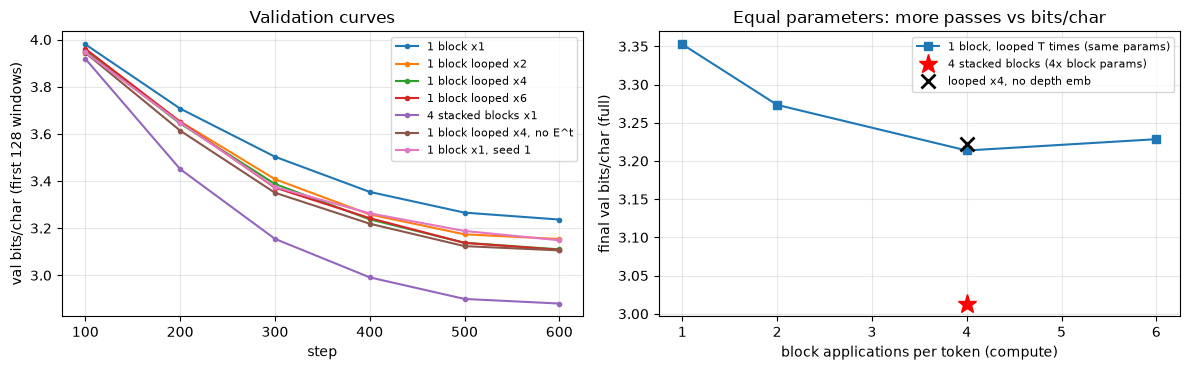

In [22]:
print(f"{'model':<26} | {'params':>8} | {'block params':>12} | {'compute':>7} | {'train bpc':>9} | {'val bits/char':>13} | {'train s':>7} | {'s / 100 steps':>13}")
print("-" * 116)
for r in results.values():
    print(f"{r['name']:<26} | {r['params']:>8,} | {r['block_params']:>12,} | {r['compute']:>7} | "
          f"{r['train_bpc']:>9.3f} | {r['val_bpc']:>13.4f} | {r['seconds']:>7.1f} | {100 * r['seconds'] / STEPS:>13.2f}")

assert results["1 block looped x4"]["params"] == results["1 block x1"]["params"], "looping must not add parameters"
seed_noise = abs(results["1 block x1"]["val_bpc"] - results["1 block x1, seed 1"]["val_bpc"])
print(f"\nseed-to-seed difference for the same config (1 block x1): {seed_noise:.4f} bits/char")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for r in results.values():
    ax[0].plot(r["hist"]["val_step"], r["hist"]["val_bpc"], "o-", label=r["name"], ms=3)
ax[0].set_xlabel("step"); ax[0].set_ylabel("val bits/char (first 128 windows)")
ax[0].set_title("Validation curves"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3)
loop_names = ["1 block x1", "1 block looped x2", "1 block looped x4", "1 block looped x6"]
ax[1].plot([results[n]["compute"] for n in loop_names], [results[n]["val_bpc"] for n in loop_names],
           "s-", label="1 block, looped T times (same params)")
s4 = results["4 stacked blocks x1"]
ax[1].plot([s4["compute"]], [s4["val_bpc"]], "r*", ms=14, label="4 stacked blocks (4x block params)")
nd = results["1 block looped x4, no E^t"]
ax[1].plot([nd["compute"]], [nd["val_bpc"]], "kx", ms=10, mew=2, label="looped x4, no depth emb")
ax[1].set_xlabel("block applications per token (compute)"); ax[1].set_ylabel("final val bits/char (full)")
ax[1].set_title("Equal parameters: more passes vs bits/char"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

**Reading Experiment A (600 steps, one seed per config, d = 128).**
* **Run-to-run noise is large.** The same "1 block x1" config with another seed (different init and batch order) gives 3.261 instead of 3.353 bits/char, a gap of **0.09 bits/char**. Differences smaller than about 0.1 in this table should not be trusted.
* **Looping at equal parameters helps, though not by much more than the noise.** 1 block x1 gets 3.353, x2 gets 3.273 and x4 gets 3.214 (-0.14 vs x1). x6 (3.229) is no better than x4. The gain from more passes saturates quickly here, and on validation x2/x4/x6 are within noise of each other. Train bits/char (last 50 steps) decreases steadily: 2.718 → 2.581 → 2.500 → 2.482.
* **At equal compute, the stack wins clearly.** 4 different blocks (3.6x the parameters, same 4 block applications) reach **3.013**, which is 0.20 below the looped x4. That is about twice the seed noise. With this tiny budget, **parameters matter more than reusing compute**. This matches the usual finding that a shared block is a parameter-efficiency trick, not a free lunch. Universal Transformers win in the paper on algorithmic tasks and at equal *parameters*, which is the comparison where we also see a gain.
* **The numbers are high, and they are not converged.** 3.0-3.35 bits/char is far from what char-level models reach on large corpora, for two measured reasons. (1) A large generalisation gap: train ≈ 2.0-2.7 vs val ≈ 3.0-3.35 bits/char. The corpus is small (~129k training chars, ~9.5 epochs in 600 steps x 32 x 64), and validation is the *last* 10% (other modules, other vocabulary), so it is distribution-shifted. (2) The validation curves are still falling at step 600. Only the *ordering* of configs is the point here.
* **Wall-clock times are unreliable on this machine.** Other jobs were running at the same time, and the same "1 block x1" config took 2.3 to 7 s per 100 steps across runs. In principle compute is proportional to block applications. Treat the `train s` column as indicative only.

### 8.1 Experiment B: changing the number of passes at test time

A looped model can be run with any $T$ - the weights do not care. Does a model trained with $T=4$ benefit from extra passes at test time, or does it break? We compare the variants with and without $E^t$ (for $t>4$ the depth embedding is a code the model has **never seen**).

test-time passes T               1       2       3       4       5       6       8
1 block looped x4            4.058   3.489   3.268   3.214   3.242   3.319   3.562
1 block looped x4, no E^t    4.061   3.514   3.282   3.223   3.242   3.303   3.491


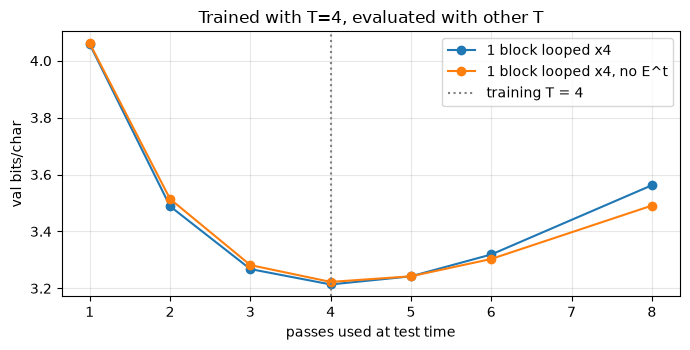

logit lens on validation text (T=4 model), bits/char after h0..h4: ['6.179', '4.058', '3.489', '3.268', '3.214']


In [23]:
test_Ts = [1, 2, 3, 4, 5, 6, 8]
extrap = {}
for name in ["1 block looped x4", "1 block looped x4, no E^t"]:
    extrap[name] = [evaluate_bpc(results[name]["model"], n_loops=T) for T in test_Ts]

print(f"{'test-time passes T':<26}" + "".join(f"{T:>8}" for T in test_Ts))
for name, vals in extrap.items():
    print(f"{name:<26}" + "".join(f"{v:>8.3f}" for v in vals))

plt.figure(figsize=(7, 3.6))
for name, vals in extrap.items():
    plt.plot(test_Ts, vals, "o-", label=name)
plt.axvline(4, color="gray", ls=":", label="training T = 4")
plt.xlabel("passes used at test time"); plt.ylabel("val bits/char")
plt.title("Trained with T=4, evaluated with other T")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

# logit lens on real text: bits/char decoded after each pass for the T=4 model
with torch.no_grad():
    m4 = results["1 block looped x4"]["model"].eval()
    _, hid = m4(VAL_X[:256], return_hidden=True)
    lens_bpc = [F.cross_entropy(m4.readout(h).flatten(0, 1), VAL_Y[:256].flatten()).item() / math.log(2) for h in hid]
    m4.train()
print("logit lens on validation text (T=4 model), bits/char after h0..h4:", [f"{v:.3f}" for v in lens_bpc])

**Reading Experiment B.**
* **At the training depth, the depth embedding made no measurable difference:** 3.214 with $E^t$ vs 3.223 without. The 0.009 gap is 10x smaller than the seed noise. The data-dependent state $h_{t-1}$ already tells the block "where it is", and §3.3 showed that neighbouring $E^t$ codes are 0.97 cosine-similar, so the signal is weak.
* **Neither model can use more passes at test time.** Both are best at exactly the trained $T=4$ and get worse beyond it: at $T=8$, 3.562 with $E^t$ and 3.491 without. **With $E^t$ the degradation is slightly worse**, plausibly because $E^5..E^8$ are codes the model never saw (a single seed, so treat this as suggestive). This contradicts the hope that "just loop more at inference" improves a plainly trained UT. It needs training with variable depth (exercise 1, and [notebook 03](03_recurrent_depth.ipynb)).
* **Fewer passes break the model badly** (T = 1: 4.06 bits/char). The logit lens on real text tells the same story: 6.18 → 4.06 → 3.49 → 3.27 → 3.21 bits/char after $h_0..h_4$. Every pass helps, with diminishing returns, and the model has learned to deliver its answer *exactly* at the trained depth.

## 9. Common pitfalls & debugging tips

* **Embedding scale vs depth embedding.** $E^t$ has entries of size ~1. If your token embedding is initialised at std 0.02, the fixed depth code dominates $h$ at the start. We kept `nn.Embedding`'s $\mathcal{N}(0,1)$ init so the two are comparable.
* **Causal-mask convention.** For `nn.MultiheadAttention`, a *boolean* `attn_mask` uses `True` = **blocked**. A float mask is *added* to the scores, so use `-inf` for blocked entries. Getting this backwards silently trains a model that peeks at the answer: its loss drops suspiciously fast and generation is garbage. Always run the "perturb position j, check outputs < j unchanged" test (§3.1, §4).
* **Do not trust a single seed.** Here one seed change moved the result by 0.09 bits/char, about as much as going from 1 to 4 passes. Compare configs with the same batches (we used a shared generator) and, ideally, several seeds.
* **Wall-clock on a shared CPU is noisy.** Count block applications for compute, and time things only when the machine is idle.
* **Test-time depth ≠ training depth.** A model trained at fixed $T$ is tuned to that $T$. Running more passes made it *worse* here (§8.1).
* **Logit-lens caveat.** Intermediate read-outs use the final LayerNorm and head, which were trained only on $h_T$. Low accuracy at an early pass may mean "not readable yet", not necessarily "not computed yet".
* **Small, shifted validation sets** (14k chars from different modules) give a big train/val gap. Report both numbers so the reader can see it.

In [24]:
total_minutes = (time.time() - NOTEBOOK_START) / 60
print(f"total notebook runtime: {total_minutes:.1f} min")

total notebook runtime: 12.7 min


## 10. Recap

* A **Universal / looped transformer** applies **one** block $T$ times: $h_t = \text{Block}(h_{t-1}+E^t)$. Parameters are independent of $T$ (232k here for any $T$, against 827k for a 4-block stack). Compute grows linearly with $T$.
* We wrote causal multi-head attention by hand. It matches `nn.MultiheadAttention` to $1.8\times10^{-7}$, and it provably does not leak future tokens.
* **Weight tying = gradient summation.** Untied per-pass copies through `functional_call` give per-pass gradients that sum to the shared gradient up to $4\times10^{-9}$.
* Toy corpus: one block x6 reaches the irreducible loss (0.0300 vs floor 0.0295 nats). The logit lens shows that **2 passes are enough** and passes 3-6 are idle.
* Docstrings, at equal parameters: looping helps (3.35 → 3.21 bits/char for T = 1 → 4), but by only ~1.5x the seed noise, and T = 6 is no better than T = 4. At equal compute, a 4-block stack is clearly better (3.01).
* The sinusoidal depth embedding did not measurably help at the trained depth. Neither variant benefits from extra passes at test time.

### Cheat sheet

| Concept | One line | Code |
|---|---|---|
| Looped / Universal Transformer | one block, applied $T$ times | `for t in 1..T: h = block(h + E[t])` |
| Parameters | independent of $T$ | `12 d^2 + 13 d` per distinct block |
| Compute | $\propto T$ block applications | `model.block_applications()` |
| Depth embedding | sinusoid of the pass index, added before each pass | `sinusoidal_depth_embedding(T, d)[t]` |
| Causal mask | `True` above the diagonal = hidden | `torch.triu(ones(L, L, bool), 1)` |
| Weight tying | shared grad = sum of per-pass grads | `functional_call(block, params_t, (h,))` |
| Logit lens | read out an intermediate $h_t$ | `model.readout(hidden[t])` |
| Bits per char | cross-entropy / ln 2 | `loss / math.log(2)` |

### Exercises

1. **Train with a random number of passes.** Sample $T\sim\{2,\dots,6\}$ every training step and evaluate at $T=1..8$. Does the test-time curve from §8.1 become flat or even improve beyond the training range?
   *Hint:* `model(x, n_loops=random.randint(2, 6))` inside the loop; nothing else needs to change. Notebook 03 (recurrent depth) does this properly.
2. **Learned vs sinusoidal depth embedding.** Replace the buffer with `nn.Embedding(max_loops + 1, d)` and repeat Experiment B.
   *Hint:* initialise it to zeros so training starts from the "no $E^t$" model; compare the extrapolation curve for $T>4$ (rows the model never trained).
3. **Equal compute, more parameters.** Add "2 distinct blocks looped x2" (`n_distinct=2, n_loops=2`) to Experiment A. Where does it land between "1 block x4" and "4 stacked blocks"?
   *Hint:* `run_config("2 blocks x2", 2, 2, True)`; compare both `params` and `val_bpc`. Notebook 08 explores such schedules.

### References

* Dehghani, Gouws, Vinyals, Uszkoreit, Kaiser. *Universal Transformers.* arXiv:1807.03819 (2018).
* Vaswani et al. *Attention Is All You Need.* arXiv:1706.03762 (2017).
* nostalgebraist. *interpreting GPT: the logit lens* (LessWrong blog post, 2020) - the origin of the "logit lens" name.